# 5. A real city from public data: Chicago

This is what an analyst would do with nothing but a city's open-data portal. It downloads weekly influenza-like-illness activity by ZIP code and the ZIP boundaries, builds the city, checks it, backtests, and forecasts.

**The data:** the Chicago Department of Public Health's *Influenza Risk Level by ZIP Code* ([data portal 8vvr-jv2g](https://data.cityofchicago.org/d/8vvr-jv2g)), compiled from Illinois' ESSENCE emergency-department syndromic surveillance. The boundaries come from *Boundaries - ZIP Codes* ([unjd-c2ca](https://data.cityofchicago.org/d/unjd-c2ca)). Both are public. All data are provisional, per the City's terms.

> **Read this first: the target is not a rate.** Each ZIP's weekly *ILI activity level* runs from 1 to 10. It compares that ZIP's percent of ED visits for ILI with the same ZIP's summer average: level 1 is below the summer mean, and each level after that is roughly one more standard deviation above it, capped at 10. So the models forecast an activity index. Comparing against persistence still makes sense, but the numbers are levels, not cases per 100,000.

> **Speed.** Chicago has 59 ZIP areas, which makes one graph-model ensemble member take about 11 minutes. This notebook uses 1 graph-model member and 2 members for the other models, and takes about 75 minutes. For real use, drop `configs=SMALL`.

In [1]:
import warnings
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

import areafluforecast as af

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110
import io, json
from pathlib import Path
import requests

## 1. Download (cached, so reruns work offline)

In [2]:
CACHE = Path("data/chicago_cache"); CACHE.mkdir(parents=True, exist_ok=True)

def socrata_csv(dataset, **params):
    """A Chicago open-data table as a DataFrame, cached on disk."""
    path = CACHE / f"{dataset}.csv"
    if not path.exists():
        r = requests.get(f"https://data.cityofchicago.org/resource/{dataset}.csv",
                         params={"$limit": 500000, **params}, timeout=300)
        r.raise_for_status()
        path.write_text(r.text)
    return pd.read_csv(path)

def socrata_geojson(dataset):
    path = CACHE / f"{dataset}.geojson"
    if not path.exists():
        r = requests.get(f"https://data.cityofchicago.org/resource/{dataset}.geojson",
                         params={"$limit": 1000}, timeout=300)
        r.raise_for_status()
        path.write_text(r.text)
    return json.loads(path.read_text())

ili = socrata_csv("8vvr-jv2g", **{"$select": "week_start,zip_code,ili_activity_level"})
ili["week_start"] = pd.to_datetime(ili["week_start"])
zips = socrata_geojson("unjd-c2ca")
print(f"{len(ili):,} ZIP-weeks, {ili.zip_code.nunique()} ZIPs, "
      f"{ili.week_start.min().date()} to {ili.week_start.max().date()}; "
      f"{len(zips['features'])} ZIP polygons")

20,432 ZIP-weeks, 60 ZIPs, 2019-09-29 to 2026-09-20; 59 ZIP polygons


In [3]:
ili.ili_activity_level.value_counts().sort_index().rename("ZIP-weeks").to_frame().T

ili_activity_level,1,2,3,4,5,6,7,8,9,10
ZIP-weeks,9771,1875,1510,1341,1017,807,620,468,364,2659


Level 10 is common because the scale is capped. During a strong season, many ZIPs sit at the ceiling for weeks.

## 2. Match the two sources

In [4]:
rates = ili.pivot_table(index="week_start", columns="zip_code", values="ili_activity_level")
rates.columns = rates.columns.astype(str)
mapped = {f["properties"]["zip"] for f in zips["features"]}
print("ZIPs with data but no polygon (dropped):", sorted(set(rates.columns) - mapped))
print("ZIPs with a polygon but no data:", sorted(mapped - set(rates.columns)))
rates = rates[sorted(set(rates.columns) & mapped)]

ZIPs with data but no polygon (dropped): ['60106']
ZIPs with a polygon but no data: []


## 3. Build the city, add weather, and check it

In [5]:
city = af.City.from_frames("chicago", rates, polygons=zips["features"], id_col="zip",
                          label="Chicago (ILI activity level)")
city.fetch_weather(verbose=False)       # Open-Meteo, free, cached
print(city.summary())

Chicago (ILI activity level): 59 areas, 365 weeks (2019-09-29 to 2026-09-20), flu season Oct-Mar
  graph: 115 borders between areas
  missing area-weeks: 5.4%
  weather: yes | static characteristics: none
  complete seasons available to backtest: 2022-23, 2023-24, 2024-25, 2025-26
  note: 19 whole weeks were absent and are treated as missing.


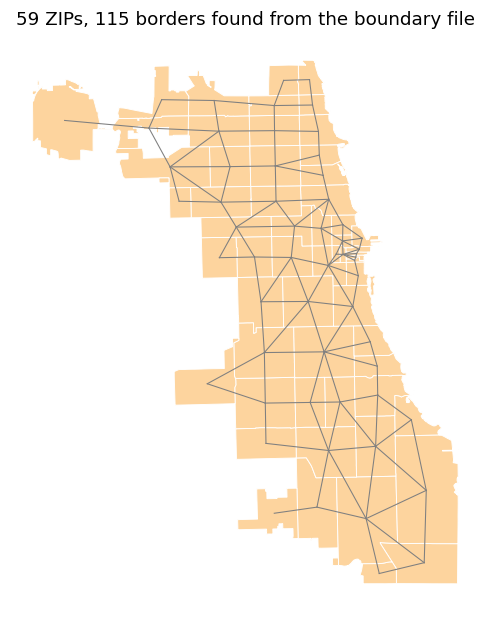

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 7))
for f in zips["features"]:
    for poly in f["geometry"]["coordinates"]:
        ax.fill(*zip(*[(x, y) for x, y, *_ in poly[0]]), color="#fdd49e", ec="white", lw=0.6)
cent = city.centroids
for a, b in city.edges:
    ax.plot(*zip(cent[a][::-1], cent[b][::-1]), color="grey", lw=0.7)
ax.set_aspect(1.35); ax.set_axis_off()
ax.set_title(f"{city.n_areas} ZIPs, {len(city.edges)} borders found from the boundary file");

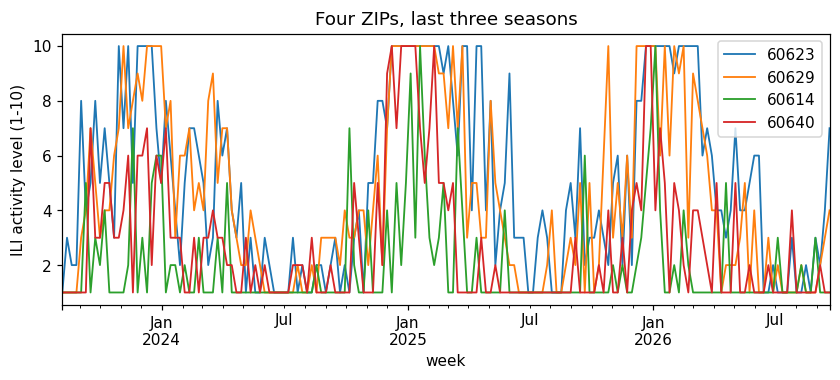

In [7]:
ax = city.rates[["60623", "60629", "60614", "60640"]].loc["2023-08":].plot(figsize=(9, 3.2), lw=1.2)
ax.set_ylabel("ILI activity level (1-10)"); ax.set_title("Four ZIPs, last three seasons");

## 4. Would it have worked here?

Backtest the last two complete seasons, 2024-25 and 2025-26, at 1 and 2 weeks ahead. The report now includes a **timing** section: how many weeks behind the curve each forecast runs, compared with persistence.

In [8]:
SMALL = {"gnn_st": {"n_seeds": 1}, "lstm": {"n_seeds": 2}, "colagnn": {"n_seeds": 2}}
bt = af.backtest(city, seasons=2, horizons=(1, 2), configs=SMALL, out_dir="runs")

Budget: 28 epochs x 1 seeds


--- seed 1 (1/1) ---


Chicago (ILI activity level): 59 areas, 365 weeks (2019-09-29 to 2026-09-20), flu season Oct-Mar
  graph: 115 borders between areas
  missing area-weeks: 5.4%
  weather: yes | static characteristics: none
  complete seasons available to backtest: 2022-23, 2023-24, 2024-25, 2025-26
  note: 19 whole weeks were absent and are treated as missing.


Epoch 1 |   3.6% | 2024-25 1wk gnn_st seed 42 | elapsed 15m04s | left ~6h46m


Epoch 2 |   7.1% | 2024-25 1wk lstm seed 42 | elapsed 15m04s | left ~3h16m


...

Epoch 26 |  92.9% | 2025-26 2wk colagnn seed 43 | elapsed 1h39m | left ~7m39s


Epoch 27 |  96.4% | 2025-26 2wk persistence | elapsed 1h39m | left ~3m41s


Epoch 28 | 100.0% | 2025-26 2wk seasonal_naive | elapsed 1h39m | left ~0m00s


Outputs: runs/chicago/backtest_20261005-151953


# Backtest: chicago

Seasons: 2024-25, 2025-26. Every number is from weeks the models never trained on.

**Relative WIS** is the model's weighted interval score divided by persistence's on the same weeks: below 1 means it beat "next week looks like this week". **p (Holm)** asks whether the weekly gap is bigger than week-to-week noise, adjusted for the number of comparisons.

| weeks ahead | model | WIS | relative WIS | p (Holm) | verdict |
|---|---|---|---|---|---|
| 1 | gnn_st | 1.06 | 0.81 | 0.000 | better than persistence |
| 1 | colagnn | 1.08 | 0.82 | 0.000 | better than persistence |
| 1 | lstm | 1.11 | 0.85 | 0.000 | better than persistence |
| 1 | seasonal_naive | 1.54 | 1.17 | 0.000 | worse than persistence |
| 2 | gnn_st | 1.11 | 0.81 | 0.000 | better than persistence |
| 2 | colagnn | 1.13 | 0.82 | 0.000 | better than persistence |
| 2 | lstm | 1.25 | 0.91 | 0.009 | better than persistence |
| 2 | seasonal_naive | 1.53 | 1.12 | 0.009 | worse than persistence |

**Timing.** I

In [9]:
display(Markdown(bt.report(show=False)))

# Backtest: chicago

Seasons: 2024-25, 2025-26. Every number is from weeks the models never trained on.

**Relative WIS** is the model's weighted interval score divided by persistence's on the same weeks: below 1 means it beat "next week looks like this week". **p (Holm)** asks whether the weekly gap is bigger than week-to-week noise, adjusted for the number of comparisons.

| weeks ahead | model | WIS | relative WIS | p (Holm) | verdict |
|---|---|---|---|---|---|
| 1 | gnn_st | 1.06 | 0.81 | 0.000 | better than persistence |
| 1 | colagnn | 1.08 | 0.82 | 0.000 | better than persistence |
| 1 | lstm | 1.11 | 0.85 | 0.000 | better than persistence |
| 1 | seasonal_naive | 1.54 | 1.17 | 0.000 | worse than persistence |
| 2 | gnn_st | 1.11 | 0.81 | 0.000 | better than persistence |
| 2 | colagnn | 1.13 | 0.82 | 0.000 | better than persistence |
| 2 | lstm | 1.25 | 0.91 | 0.009 | better than persistence |
| 2 | seasonal_naive | 1.53 | 1.12 | 0.009 | worse than persistence |

**Timing.** Is the forecast late? *Weeks behind the curve* is how far the forecast would have to be slid earlier to fit best; persistence is exactly h weeks behind by construction. See areafluforecast.timing for why every model here tends to run late.

- colagnn, 1 wk ahead: 1 week(s) behind the curve (no earlier than persistence); 30% of its squared error is timing; peaks a median 3.5 week(s) late
- gnn_st, 1 wk ahead: 1 week(s) behind the curve (no earlier than persistence); 43% of its squared error is timing; peaks a median 3.5 week(s) late
- lstm, 1 wk ahead: 1 week(s) behind the curve (no earlier than persistence); 7% of its squared error is timing; peaks a median 4 week(s) late
- persistence, 1 wk ahead: 1 week(s) behind the curve (exactly 1 by construction)
- seasonal_naive, 1 wk ahead: does not follow the recent curve (it copies an earlier season), so 'weeks behind' does not apply; its peak is a median -1.5 week(s) off
- colagnn, 2 wk ahead: 2 week(s) behind the curve (no earlier than persistence); 29% of its squared error is timing; peaks a median 4 week(s) late
- gnn_st, 2 wk ahead: 2 week(s) behind the curve (no earlier than persistence); 42% of its squared error is timing; peaks a median 4 week(s) late
- lstm, 2 wk ahead: 2 week(s) behind the curve (no earlier than persistence); 11% of its squared error is timing; peaks a median 4.5 week(s) late
- persistence, 2 wk ahead: 2 week(s) behind the curve (exactly 2 by construction)
- seasonal_naive, 2 wk ahead: does not follow the recent curve (it copies an earlier season), so 'weeks behind' does not apply; its peak is a median -1.5 week(s) off

Coverage of the 95% band (should be near 95%):

- colagnn, 1 wk: 95.8%
- gnn_st, 1 wk: 95.8%
- lstm, 1 wk: 95.7%
- persistence, 1 wk: 96.1%
- seasonal_naive, 1 wk: 97.4%
- colagnn, 2 wk: 95.9%
- gnn_st, 2 wk: 95.7%
- lstm, 2 wk: 94.2%
- persistence, 2 wk: 96.7%
- seasonal_naive, 2 wk: 97.4%

In [10]:
bt.timing.round(2)

,model,horizon,weeks_late,timing_share,lag_fingerprint,peak_weeks_late,seasons
0,colagnn,1,1.0,0.30,-0.77,3.5,2
1,colagnn,2,2.0,0.29,-0.66,4.0,2
2,gnn_st,1,1.0,0.43,-0.82,3.5,2
3,gnn_st,2,2.0,0.42,-0.65,4.0,2
4,lstm,1,1.0,0.07,-0.67,4.0,2
5,lstm,2,2.0,0.11,-0.62,4.5,2
6,persistence,1,1.0,1.00,-1.00,1.0,2
7,persistence,2,2.0,1.00,-0.53,2.0,2
8,seasonal_naive,1,0.0,0.00,-0.43,-1.5,2
9,seasonal_naive,2,0.0,0.00,-0.43,-1.5,2


**How to read the timing lines.** Persistence is exactly *h* weeks behind by construction. A model that is also *h* weeks behind gets its advantage from the size of the curve, not from seeing turns earlier. In the research behind this package, that was true of every model, including the tuned 10-member ones. Forecasting the turn earlier needs inputs that move before ED visits do, such as wastewater or a shorter reporting delay. More past rates won't do it.

*Chicago caveat:* the level is capped at 10, so an observed peak is often a run of 10s, and "peaks N weeks late" picks the first week of that run. Trust the weeks-behind figure here more than the peak offset.

## 5. Forecast

In [11]:
fc = af.forecast(city, horizons=(1, 2), configs=SMALL, out_dir="runs")
fc.trust

Budget: 10 epochs x 1 seeds


--- seed 1 (1/1) ---


Epoch 1 |  10.0% | 1wk gnn_st seed 42 | elapsed 14m01s | left ~2h06m


Epoch 2 |  20.0% | 1wk lstm seed 42 | elapsed 14m01s | left ~56m07s


Epoch 3 |  30.0% | 1wk lstm seed 43 | elapsed 14m02s | left ~32m46s


...

Epoch 8 |  80.0% | 2wk lstm seed 43 | elapsed 31m55s | left ~7m58s


Epoch 9 |  90.0% | 2wk colagnn seed 42 | elapsed 34m22s | left ~3m49s


Epoch 10 | 100.0% | 2wk colagnn seed 43 | elapsed 35m50s | left ~0m00s


Outputs: runs/chicago/forecast_20261005-151954


,model,horizon,trust
0,gnn_st,1,better than persistence
1,gnn_st,2,better than persistence
2,lstm,1,better than persistence
3,lstm,2,better than persistence
4,colagnn,1,better than persistence
5,colagnn,2,better than persistence


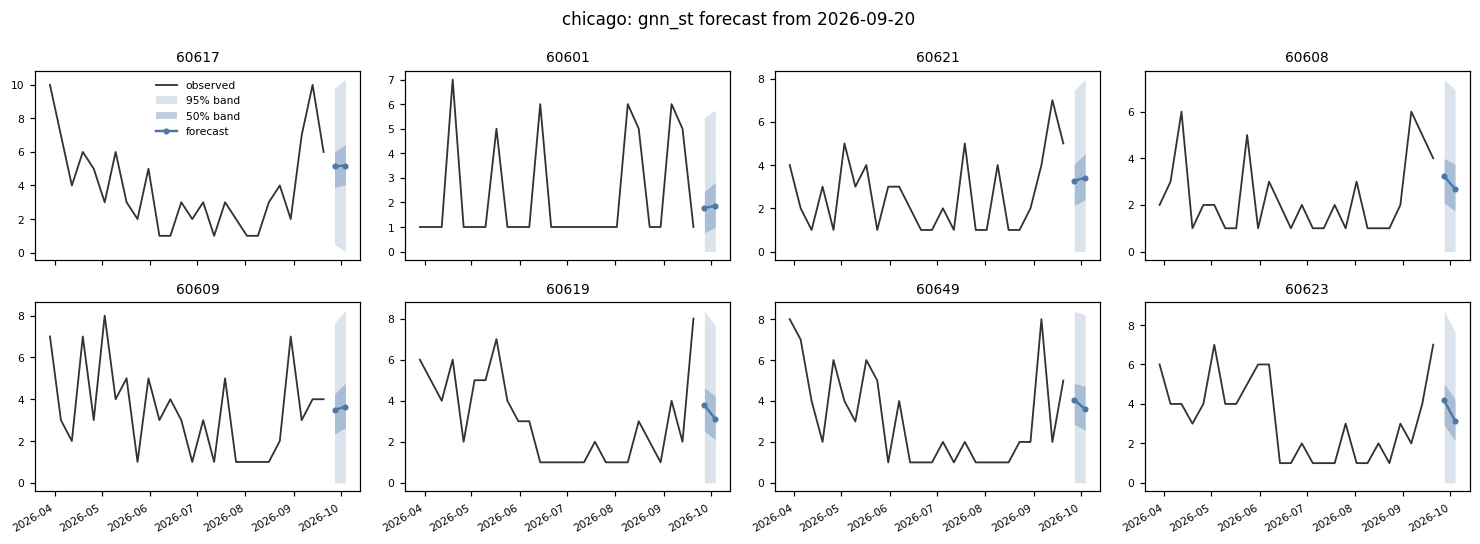

In [12]:
busiest = city.rates.iloc[-8:].mean().nlargest(8).index.tolist()
fig = fc.plot("gnn_st", areas=busiest)

In [13]:
fc.to_flusight("gnn_st").head()

,model,reference_date,target,horizon,target_end_date,location,output_type,output_type_id,value
0,gnn_st,2026-09-20,wk inc flu rate,1,2026-09-27,60601,quantile,0.010,0.000000
1,gnn_st,2026-09-20,wk inc flu rate,1,2026-09-27,60601,quantile,0.025,0.000000
2,gnn_st,2026-09-20,wk inc flu rate,1,2026-09-27,60601,quantile,0.050,0.000000
3,gnn_st,2026-09-20,wk inc flu rate,1,2026-09-27,60601,quantile,0.100,0.000000
4,gnn_st,2026-09-20,wk inc flu rate,1,2026-09-27,60601,quantile,0.150,0.256251


## What this example shows, and what it doesn't

- **Shows:** the whole pipeline runs on a real city from two public downloads. The map comes from the boundary file, with no hand-drawn borders, and the backtest says honestly whether any model beat persistence here.
- **Doesn't show:** forecasts of case rates. The target is an index relative to each ZIP's summer baseline. A department with its own ESSENCE access would use ILI visit counts or percentages instead, and the same code applies.